   # Stellar Photometric Variability: Gaia DR3 pilot
   Query date 2026-10-12, Gaia DR3. Purpose: check data pulls and distributions.

In [18]:
from astroquery.gaia import Gaia
import pandas as pd
from datetime import date

query = """
SELECT TOP 2000
    v.source_id, v.best_class_name, v.best_class_score,
    g.phot_g_mean_mag, g.bp_rp, g.parallax, g.parallax_over_error
FROM gaiadr3.vari_classifier_result AS v
JOIN gaiadr3.gaia_source AS g USING (source_id)
"""

job = Gaia.launch_job(query)
df = job.get_results().to_pandas()

print("Query date:", date.today(), "| Release: Gaia DR3")
print(df.shape)

Query date: 2026-10-12 | Release: Gaia DR3
(2000, 7)


In [19]:
df.to_csv("../data/raw/gaia_dr3_pilot2000_raw.csv", index=False)

In [20]:
df.head(10)

,source_id,best_class_name,best_class_score,phot_g_mean_mag,bp_rp,parallax,parallax_over_error
0,138839529424242688,AGN,0.299949,20.085274,0.521372,0.270579,0.448866
1,138900513663814016,AGN,0.077067,20.673962,0.879650,-1.255990,-1.237194
2,138920687125960320,SOLAR_LIKE,0.398601,13.574021,1.141584,2.687883,158.489349
3,139028989021035136,DSCT|GDOR|SXPHE,0.726662,13.451948,0.715099,0.843904,50.063919
4,139150858717750912,AGN,0.926235,19.618536,0.701525,-0.220511,-0.576056
5,139306650067792640,LPV,0.147445,20.012352,2.599180,NaN,NaN
6,139341765719939328,RS,0.043103,17.480667,1.679897,0.836981,7.354224
7,139389525756197632,RS,0.749563,14.597960,1.072809,1.187699,42.986729
8,139445875726880512,S,0.526388,17.429911,1.361559,NaN,NaN
9,139500847018497536,LPV,0.114995,19.257236,2.953674,-4.825063,-4.888407


## 2. Class counts and missing values

In [21]:
print(df["best_class_name"].value_counts())
print()
print(df.isna().mean().round(3))

best_class_name
ECL                           468
AGN                           456
DSCT|GDOR|SXPHE               335
SOLAR_LIKE                    288
RS                            280
S                              77
LPV                            67
RR                             12
CV                              5
ACV|CP|MCP|ROAM|ROAP|SXARI      4
YSO                             4
SN                              1
WD                              1
BCEP                            1
CEP                             1
Name: count, dtype: int64

source_id              0.000
best_class_name        0.000
best_class_score       0.000
phot_g_mean_mag        0.000
bp_rp                  0.003
parallax               0.054
parallax_over_error    0.054
dtype: float64


## 3. Removing AGN (not stars)

In [22]:
stars = df[df["best_class_name"] != "AGN"].copy()
print(len(stars))
print(stars["best_class_name"].value_counts().head(8))
print(stars["best_class_score"].describe().round(2))

1544
best_class_name
ECL                468
DSCT|GDOR|SXPHE    335
SOLAR_LIKE         288
RS                 280
S                   77
LPV                 67
RR                  12
CV                   5
Name: count, dtype: int64
count    1544.00
mean        0.48
std         0.28
min         0.00
25%         0.24
50%         0.44
75%         0.71
max         1.00
Name: best_class_score, dtype: float64


## 4. Finding the amplitude table

In [23]:
tables = Gaia.load_tables(only_names=True)
vari = [t.name for t in tables if "vari" in t.name]
for name in vari:
    print(name)

INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]
INFO: Done. [astroquery.utils.tap.core]
gaiadr1.phot_variable_time_series_gfov
gaiadr1.phot_variable_time_series_gfov_statistical_parameters
gaiadr1.variable_summary
gaiadr2.vari_cepheid
gaiadr2.vari_classifier_class_definition
gaiadr2.vari_classifier_definition
gaiadr2.vari_classifier_result
gaiadr2.vari_long_period_variable
gaiadr2.vari_rotation_modulation
gaiadr2.vari_rrlyrae
gaiadr2.vari_short_timescale
gaiadr2.vari_time_series_statistics
gaiadr3.vari_spurious_signals
gaiadr3.vari_agn
gaiadr3.vari_cepheid
gaiadr3.vari_classifier_class_definition
gaiadr3.vari_classifier_definition
gaiadr3.vari_classifier_result
gaiadr3.vari_compact_companion
gaiadr3.vari_eclipsing_binary
gaiadr3.vari_epoch_radial_velocity
gaiadr3.vari_long_period_variable
gaiadr3.vari_microlensing
gaiadr3.vari_ms_oscillator
gaiadr3.vari_planetary_transit
gaiadr3.vari_planetary_transit_13june2022
gaiadr3.vari_ra

In [24]:
t = Gaia.load_table("gaiadr3.vari_summary")
for col in t.columns:
    if "g_fov" in col.name:
        print(col.name)

num_selected_g_fov
mean_obs_time_g_fov
time_duration_g_fov
min_mag_g_fov
max_mag_g_fov
mean_mag_g_fov
median_mag_g_fov
range_mag_g_fov
trimmed_range_mag_g_fov
std_dev_mag_g_fov
skewness_mag_g_fov
kurtosis_mag_g_fov
mad_mag_g_fov
abbe_mag_g_fov
iqr_mag_g_fov
stetson_mag_g_fov
std_dev_over_rms_err_mag_g_fov
outlier_median_g_fov


## 5. Amplitude from vari_summary (G band)

In [25]:
query = """
SELECT TOP 2000
    v.source_id, v.best_class_name, v.best_class_score,
    g.phot_g_mean_mag, g.bp_rp, g.parallax, g.parallax_over_error,
    s.num_selected_g_fov, s.mean_mag_g_fov, s.range_mag_g_fov,
    s.trimmed_range_mag_g_fov, s.std_dev_mag_g_fov
FROM gaiadr3.vari_classifier_result AS v
JOIN gaiadr3.gaia_source AS g USING (source_id)
JOIN gaiadr3.vari_summary AS s USING (source_id)
WHERE v.best_class_name <> 'AGN'
"""

job = Gaia.launch_job(query)
df2 = job.get_results().to_pandas()

print("Query date:", date.today(), "| Release: Gaia DR3")
print(df2.shape)
print(df2["best_class_name"].value_counts().head(8))
print(df2.isna().mean().round(3))
df2.to_csv("../data/raw/gaia_dr3_pilot_amplitude_raw.csv", index=False)
df2.head()

Query date: 2026-10-12 | Release: Gaia DR3
(2000, 12)
best_class_name
ECL                           612
SOLAR_LIKE                    403
DSCT|GDOR|SXPHE               402
RS                            346
S                             119
LPV                            83
RR                             15
ACV|CP|MCP|ROAM|ROAP|SXARI      5
Name: count, dtype: int64
source_id                  0.000
best_class_name            0.000
best_class_score           0.000
phot_g_mean_mag            0.000
bp_rp                      0.004
parallax                   0.075
parallax_over_error        0.075
num_selected_g_fov         0.000
mean_mag_g_fov             0.000
range_mag_g_fov            0.000
trimmed_range_mag_g_fov    0.000
std_dev_mag_g_fov          0.000
dtype: float64


,source_id,best_class_name,best_class_score,phot_g_mean_mag,bp_rp,parallax,parallax_over_error,num_selected_g_fov,mean_mag_g_fov,range_mag_g_fov,trimmed_range_mag_g_fov,std_dev_mag_g_fov
0,138873683003824640,ECL,0.924358,19.544607,1.563791,0.011446,0.028005,30,19.558661,0.664789,0.628372,0.229264
1,138938313671572480,RS,0.012751,16.797878,1.129114,0.231561,2.356935,25,16.797970,0.054267,0.052843,0.014783
2,139251605766975744,ECL,0.919396,16.799919,1.362354,0.646286,9.426382,28,16.790730,0.640777,0.598037,0.240897
3,139303866929012608,ECL,0.189754,19.833242,1.343395,-0.289478,-0.600486,27,19.834879,0.285584,0.234671,0.079905
4,139382516369499776,DSCT|GDOR|SXPHE,0.244140,15.672320,0.623962,0.096978,1.563746,23,15.670148,0.047868,0.036581,0.012116


## 6. Finding period columns

In [26]:
tables_to_check = [
    "gaiadr3.vari_eclipsing_binary",
    "gaiadr3.vari_rrlyrae",
    "gaiadr3.vari_cepheid",
    "gaiadr3.vari_long_period_variable",
    "gaiadr3.vari_rotation_modulation",
    "gaiadr3.vari_short_timescale",
]

for name in tables_to_check:
    try:
        t = Gaia.load_table(name)
        cols = [c.name for c in t.columns
                if "period" in c.name or "frequency" in c.name or "amplitude" in c.name]
        print(name)
        print("   ", cols)
    except Exception as e:
        print(name, "-> failed:", str(e)[:80])

gaiadr3.vari_eclipsing_binary
    ['frequency', 'frequency_error', 'geom_model_cosine_half_period_amplitude', 'geom_model_cosine_half_period_amplitude_error', 'geom_model_cosine_half_period_phase', 'geom_model_cosine_half_period_phase_error']
gaiadr3.vari_rrlyrae
    []
gaiadr3.vari_cepheid
    []
gaiadr3.vari_long_period_variable
    ['frequency', 'frequency_error', 'amplitude']
gaiadr3.vari_rotation_modulation
    ['segments_rotation_period', 'segments_rotation_period_error', 'segments_rotation_period_fap', 'best_rotation_period', 'best_rotation_period_error']
gaiadr3.vari_short_timescale
    ['amplitude_estimate', 'frequency']


In [27]:
for name in ["gaiadr3.vari_rrlyrae", "gaiadr3.vari_cepheid"]:
    t = Gaia.load_table(name)
    print(name)
    print([c.name for c in t.columns])
    print()

gaiadr3.vari_rrlyrae
['solution_id', 'source_id', 'pf', 'pf_error', 'p1_o', 'p1_o_error', 'epoch_g', 'epoch_g_error', 'epoch_bp', 'epoch_bp_error', 'epoch_rp', 'epoch_rp_error', 'epoch_rv', 'epoch_rv_error', 'int_average_g', 'int_average_g_error', 'int_average_bp', 'int_average_bp_error', 'int_average_rp', 'int_average_rp_error', 'average_rv', 'average_rv_error', 'peak_to_peak_g', 'peak_to_peak_g_error', 'peak_to_peak_bp', 'peak_to_peak_bp_error', 'peak_to_peak_rp', 'peak_to_peak_rp_error', 'peak_to_peak_rv', 'peak_to_peak_rv_error', 'metallicity', 'metallicity_error', 'r21_g', 'r21_g_error', 'r31_g', 'r31_g_error', 'phi21_g', 'phi21_g_error', 'phi31_g', 'phi31_g_error', 'num_clean_epochs_g', 'num_clean_epochs_bp', 'num_clean_epochs_rp', 'num_clean_epochs_rv', 'zp_mag_g', 'zp_mag_bp', 'zp_mag_rp', 'num_harmonics_for_p1_g', 'num_harmonics_for_p1_bp', 'num_harmonics_for_p1_rp', 'num_harmonics_for_p1_rv', 'reference_time_g', 'reference_time_bp', 'reference_time_rp', 'reference_time_rv', '

## 7. RR Lyrae and Cepheid pull

In [28]:
q_rr = """
SELECT TOP 2000
    r.source_id, r.pf, r.p1_o, r.peak_to_peak_g, r.int_average_g,
    r.num_clean_epochs_g, r.best_classification,
    g.bp_rp, g.parallax, g.parallax_over_error
FROM gaiadr3.vari_rrlyrae AS r
JOIN gaiadr3.gaia_source AS g USING (source_id)
"""

q_cep = """
SELECT TOP 2000
    c.source_id, c.pf, c.p1_o, c.peak_to_peak_g, c.int_average_g,
    c.num_clean_epochs_g, c.type_best_classification, c.mode_best_classification,
    g.bp_rp, g.parallax, g.parallax_over_error
FROM gaiadr3.vari_cepheid AS c
JOIN gaiadr3.gaia_source AS g USING (source_id)
"""

rr = Gaia.launch_job(q_rr).get_results().to_pandas()
cep = Gaia.launch_job(q_cep).get_results().to_pandas()

print("Query date:", date.today(), "| Release: Gaia DR3")
print("RR Lyrae:", rr.shape, "| Cepheids:", cep.shape)

rr.to_csv("../data/raw/gaia_dr3_rrlyrae_pilot_raw.csv", index=False)
cep.to_csv("../data/raw/gaia_dr3_cepheid_pilot_raw.csv", index=False)

print(rr.isna().mean().round(3))
print(cep.isna().mean().round(3))

Query date: 2026-10-12 | Release: Gaia DR3
RR Lyrae: (2000, 10) | Cepheids: (2000, 11)
source_id              0.000
pf                     0.376
p1_o                   0.620
peak_to_peak_g         0.000
int_average_g          0.000
num_clean_epochs_g     0.000
best_classification    0.000
bp_rp                  0.080
parallax               0.024
parallax_over_error    0.024
dtype: float64
source_id                   0.000
pf                          0.396
p1_o                        0.606
peak_to_peak_g              0.000
int_average_g               0.000
num_clean_epochs_g          0.000
type_best_classification    0.000
mode_best_classification    0.000
bp_rp                       0.000
parallax                    0.000
parallax_over_error         0.000
dtype: float64


## 8. Combined period column

In [29]:
import numpy as np
import matplotlib.pyplot as plt

for d in (rr, cep):
    d["period"] = d["pf"].fillna(d["p1_o"])
    d["period_type"] = np.where(d["pf"].notna(), "fundamental", "overtone")

print(rr["period"].isna().sum(), cep["period"].isna().sum(), "stars with no period")
print(rr["period_type"].value_counts())
print(cep["period_type"].value_counts())

0 11 stars with no period
period_type
fundamental    1248
overtone        752
Name: count, dtype: int64
period_type
fundamental    1209
overtone        791
Name: count, dtype: int64


## 9. First scatter plots

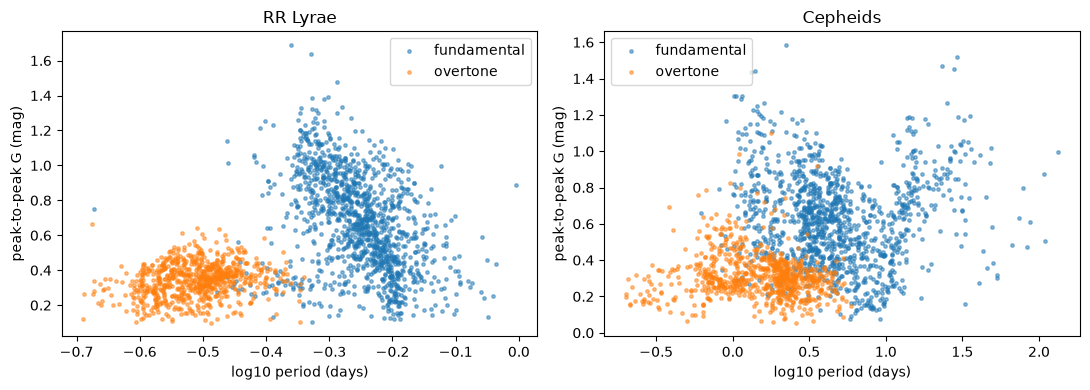

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, d, title in [(ax[0], rr, "RR Lyrae"), (ax[1], cep, "Cepheids")]:
    d2 = d.dropna(subset=["period"])
    for k, grp in d2.groupby("period_type"):
        a.scatter(np.log10(grp["period"]), grp["peak_to_peak_g"], s=6, alpha=0.5, label=k)
    a.set_xlabel("log10 period (days)")
    a.set_ylabel("peak-to-peak G (mag)")
    a.set_title(title)
    a.legend()
plt.tight_layout()
plt.show()